# **Project 2**, APS1070 Fall 2024
**Anomaly Detection Algorithm using Gaussian Mixture Model**

**Deadline: Oct 25th, 11 PM - 13 percent**

**Academic Integrity**

This project is individual - it is to be completed on your own. If you have questions, please post your query in the APS1070 Piazza Q&A forums (the answer might be useful to others!).

Do not share your code with others, or post your work online. Do not submit code that you have not written yourself without proper acknowledgment of the source, including generated code (please refer to the course syllabus). Students suspected of plagiarism on a project, midterm or exam will be referred to the department for formal discipline for breaches of the Student Code of Conduct.

Name: Tiffany Costas  *(here and elsewhere, please replace the underscore with your answer)*

Student ID: 1005854844

##**Marking Scheme:**

This project is worth **13 percent** of your final grade.

Draw a plot or table where necessary to summarize your findings.

**Practice Vectorized coding**: If you need to write a loop in your solution, think about how you can implement the same functionality with vectorized operations. Try to avoid loops as much as possible (in some cases, loops are inevitable).




### How to submit **(HTML + IPYNB)**

1. Check that the completed `.ipynb` file runs correctly when using `Runtime -> Run All`.

2. Download your notebook: `File -> Download .ipynb`

3. Click on the Files icon on the far left menu of Colab

4. Select & upload your `.ipynb` file you just downloaded, and then obtain its path (right click) (you might need to hit the Refresh button before your file shows up)


5. execute the following in a Colab cell:
```
%%shell
jupyter nbconvert --to html /PATH/TO/YOUR/NOTEBOOKFILE.ipynb
```

6. An HTML version of your notebook will appear in the files, so you can download it.

7. Submit **both** <font color='red'>`HTML` and `IPYNB`</font>  files on Quercus for grading.



Ref: https://stackoverflow.com/a/64487858



# Project 2 [13 Marks]

##**Part 1: Getting started [1.5 Marks]**

We are going to work with the [Thyroid Disease](https://odds.cs.stonybrook.edu/thyroid-disease-dataset/) dataset. This dataset contains 6 clinical attributes to determine whether a patient referred to the clinic is hypothyroid.

 The dataset is called `Thyroid_Disease.csv`. Load the dataset in CSV file using Pandas and name it `df`. Print out the first few columns of the dataset.


* How many rows are there? 3772 **[0.1]**
* Which column contains the targets? hypothyroid - the last column **[0.1]**
* To what do the target values correspond? There are only 2 outputs either 0 or 1 corresponding to either non-hypothyroid or hypothyroid - based on knowledge that 0 typically corresponds to false while 1 corresponds to true **[0.2]**

In [84]:
pip install wget

In [85]:
import wget

wget.download('https://raw.githubusercontent.com/Sabaae/Dataset/main/Thyroid_Disease.csv')

'Thyroid_Disease (1).csv'

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [87]:
### YOUR CODE HERE ###
df = pd.read_csv('Thyroid_Disease.csv')
num_rows = df.shape[0]
print("Number of Rows: ", num_rows)
target = df.columns[-1]
print("Target Column Name: ", target)
out = df[target].unique()
print("Target Column Outputs: ", out)
df.set_index(df.columns[0], inplace=True) # Unnamed:0 --> index column to clean up code
df.index.name = "Index"
df.head()

Number of Rows:  3772
Target Column Name:  hypothyroid
Target Column Outputs:  [0. 1.]


,Attribute0,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,hypothyroid
Index,,,,,,,
0,0.774194,0.001132,0.137571,0.275701,0.295775,0.236066,0.0
1,0.247312,0.000472,0.279886,0.329439,0.535211,0.173770,0.0
2,0.494624,0.003585,0.222960,0.233645,0.525822,0.124590,0.0
3,0.677419,0.001698,0.156546,0.175234,0.333333,0.136066,0.0
4,0.236559,0.000472,0.241935,0.320093,0.333333,0.247541,0.0


It's important to know how many examples we have for each class when we work with a new dataset.

* What is the percentage of entries in the dataset for each class? **For class 0: 97.53% For class 1: 2.47% [0.1]**
* Is this data considered balanced or unbalanced? Why is this the case? **The data is considered unbalanced as there is an unequal representation of the non-hypothyroid and hypothryoid classes. [0.1]**
* Why is balance/imbalance important? How might this class ditribution affect a KNN classifier for example, which we explored in Project 1? **When data is imbalanced, the model will be biased towards/favour the majority class which may skew the results and impact the performance. This class distribution would impact a KNN classifier, as this model relies on the majority vote of the nearest neighbours to classify a data point. Since the dataset is imbalanced, the majority class will have more instances making it more likely that the nearest neighbours will belong to the class. In this case, it is likely that the classifier will predominately predict the non-hypothyroid class, resulting in a poor performance when predicting the minority class. This is because the model would not have enough samples to learn the minority class' characteristics. KNNs are also sensitive to distances, so when the dataset is imbalanced, the euclidean distance measured may be skewed to favour the majority, as these points may cluster more densely in one area.  [0.2]**


In [88]:
### YOUR CODE HERE ###
pct_entries = df[target].value_counts(normalize=True)*100 #Reference: https://datagy.io/pandas-value_counts/#:~:text=In%20order%20to%20transform%20the%20counts%20into%20percentages%2C,Showing%20percentages%20of%20value%20counts%20print%20%28df%5B%27Students%27%5D.value_counts%28normalize%3D%20True%29%29
print(pct_entries)

hypothyroid
0.0    97.534464
1.0     2.465536
Name: proportion, dtype: float64


Next, split the dataset into a training (70%), validation (15%) and testing set (15%). Set the random state to 0. **[0.2]**

Make sure to separate out the column corresponding to the targets.

In [89]:
### Split the data  ###
X = df.drop(target, axis=1)
y = df[target]

#split into training and testing using train_test_split, then split the test set in half to get 15% for val and test sets.
X_train, X_split, y_train, y_split = train_test_split(X, y, test_size=0.3, random_state=0)
X_val, X_test, y_val, y_test = train_test_split(X_split, y_split, test_size=0.5, random_state=0)

Now, let's take a look at the difference in distribution for some variables between hypothyroid and not-hypothyroid patients:

Attribute0
Attribute1
Attribute2
Attribute3
Attribute4
Attribute5


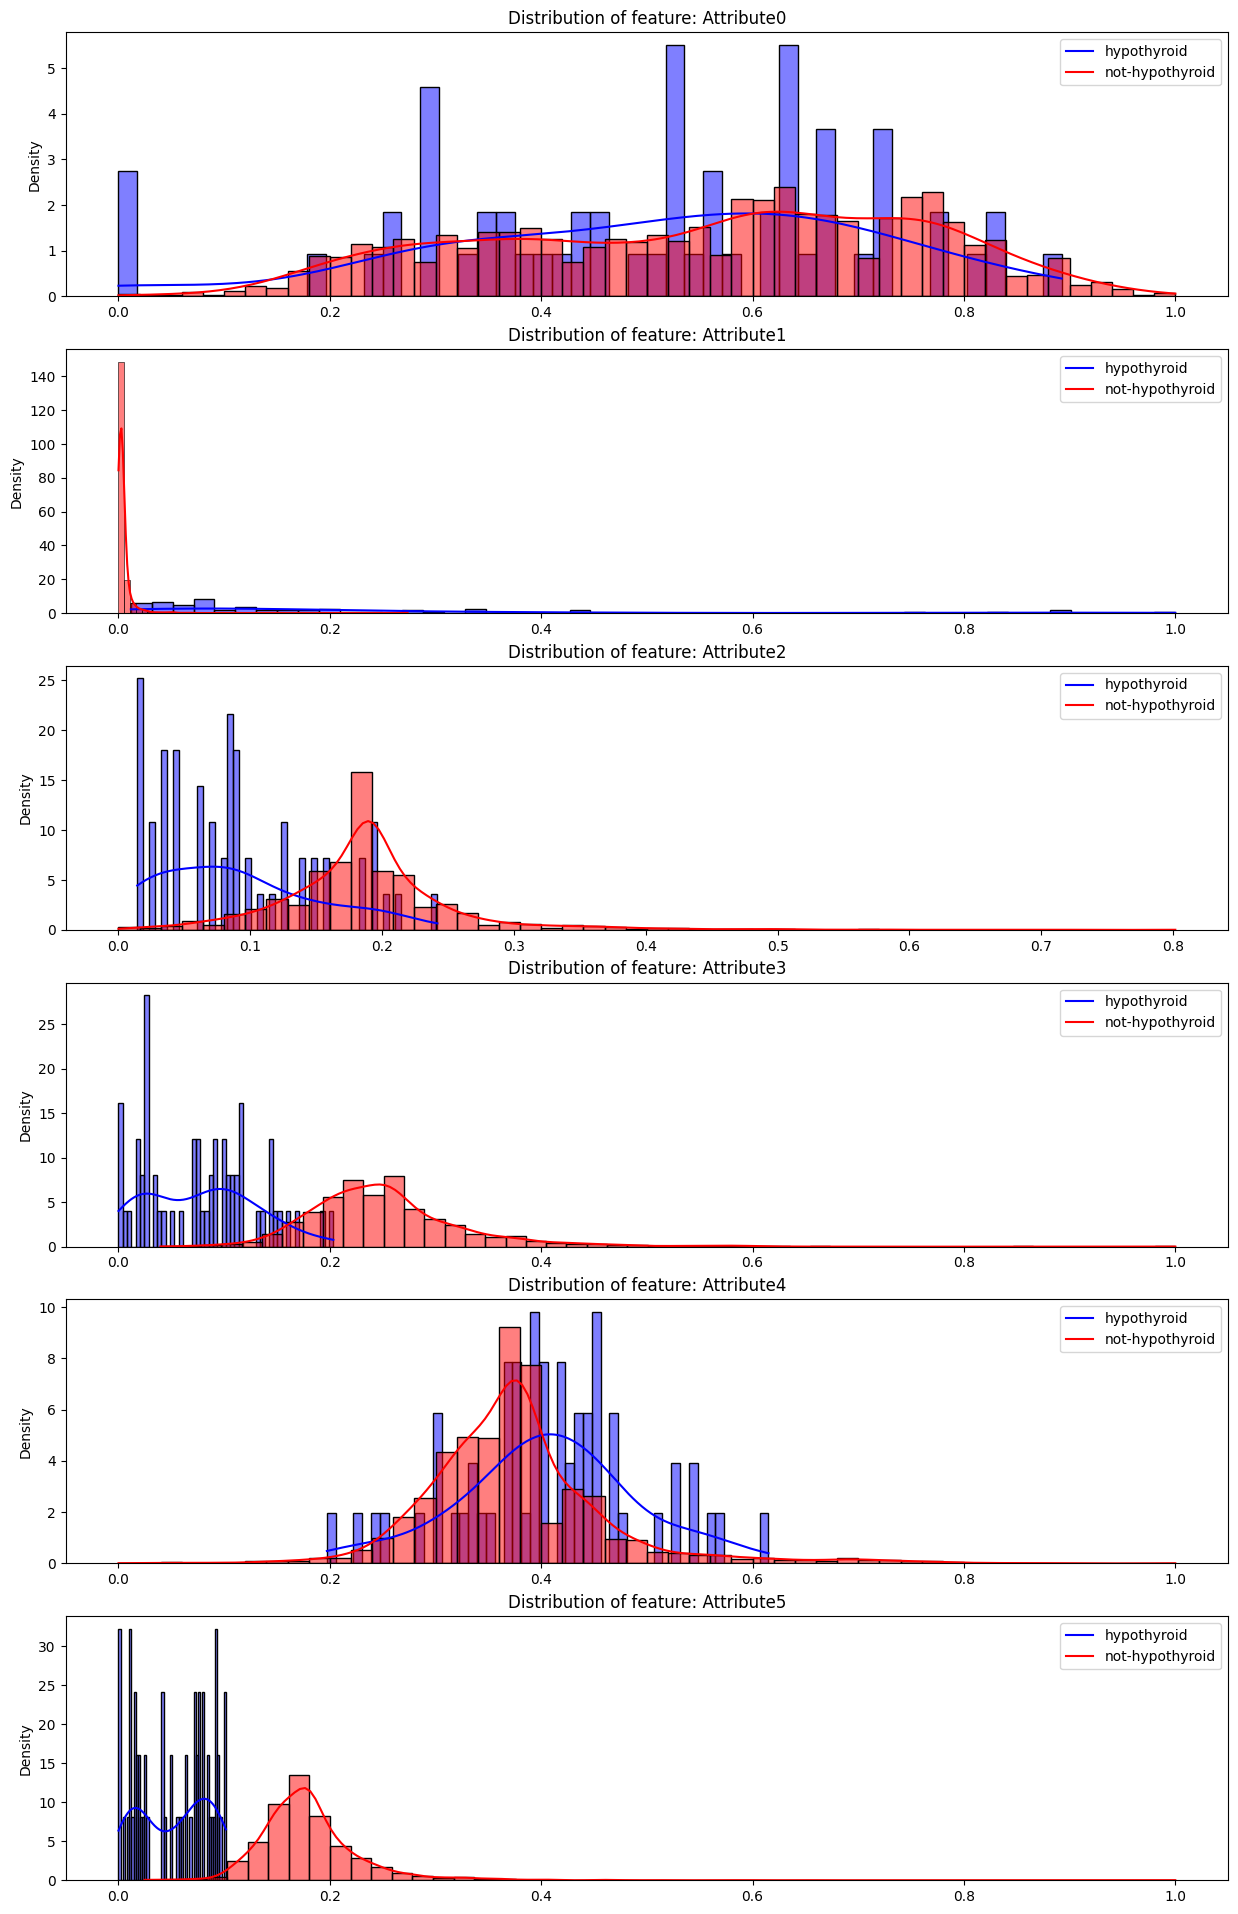

In [90]:
import matplotlib.gridspec as gridspec
features=list(df.columns[:-1])
nplots=np.size(features)
plt.figure(figsize=(15,4*nplots))
gs = gridspec.GridSpec(nplots,1)
for i, feat in enumerate(features):
    print(feat)
    ax = plt.subplot(gs[i])
    sns.histplot(X_train[feat][y_train==1], stat="density", kde=True, color="blue", bins=50)
    sns.histplot(X_train[feat][y_train==0], stat="density", kde=True, color="red", bins=50)
    ax.legend(['hypothyroid', 'not-hypothyroid'],loc='best')
    ax.set_xlabel('')
    ax.set_title('Distribution of feature: ' + feat)

Explain how these graphs could provide meaningful information about anomaly detection using a gaussian model. **[0.5]**

Answer: By analyzing the shape of the curves, the separation of the curves of the two classes, and the amount of overlap, ideal attributes/features for anomaly detection can be identified. Ideal features would closely resemble a Gaussian distribution, and appear as two distinct curves with little to no overlap. Below briefly summarizes each graph and whether or not it would make a good feature for anomaly detection.
* Attribute0: significant overlap between the two classes where both graphs exhibit a somewhat uniform distribution -> particularly both classes have various peaks. As it is difficult to distinguish between the two classes due to the overlap, this is likely a poor feature to perform anomaly detection on
* Attribute1: For the not-hypothyroid class the graph is highly skewed to the left with a long tail, while the hypothyroid class remains mainly flat. As there is strong separation between the groups, especially at lower values, a Gaussian model could treat these extreme values from the hypothyroid class as outliers.
* Attribute2: Both classes are skewed to the left (lower values), where the hypothyroid class has a wider spread. There is also a lot of overlap between the two graphs which may be difficult to distinguish anomalies
* Attribute3: Less overlap between the two classes compared to Attribute2, and the not-hypothyroid class has a wider, more dispersed distribution. The difference between the spread of both classes and the peaks indicates that the feature may be good for anomaly detection, particularly at lower values
* Attribute4: There is significant overlap between the two distributions, and they both closely resemble a Gaussian distribution. The not-hypothyroid class has a smaller range in comparison to the hypothyroid class. It may be difficult to distinguish anomalies with this feature
* Attribute5: Hypothyroid class is concentratted at lower values while the not-hypothyroid class is more spread out, and is distributed between 0.0-0.03. There is some overlap, but this feature could be useful for anomaly detection as values outside the main range of not-hypothyroid (if fitted on this class) could be detected as anomalies.

In summary, ideal features are: Attribute1, Attribute3, Attribute5

## **Part 2: Single feature model with one Gaussian distribution: [2.5 Marks]**
We'll start by making a prediction using **a single feature of our dataset at a time**.

**a. Fitting regardless of class:**
  1. Fit a single Gaussian distribution on a single feature of **the full training dataset** (both classes) using ``sklearn.mixture.GaussianMixture`` when ``n_components=1``.
  2. Compute AUC (Area under the ROC Curve) based on ``sklearn.mixture.GaussianMixture.score_samples`` on both the full training set and validation set (including both classes).  
  3. Repeat the above steps for each of the features and present your findings in a table.
  4. Find the best 3 features to distinguish hypothyroid patients from not-hypothyroid patients based on the AUC of the validation set. **[0.2]**
  5. Make a prediction based on a model's scores: If the `score_samples` is lower than a threshold, we consider that patient as hypothyroid. Find an optimal threshold that maximizes the F1 Score of the validation set for each of those 3 features separately. (Do not check every possible value for threshold, come up with a faster way!) Compute F1 score using `sklearn.metrics.f1_score`. **[0.5]**
  6. Report the complexity of your method (Big O notation) for determining the optimal threshold.**[0.5]**

**b. Fitting based on class:**
 1. Pick 3 features that had the best AUC in Part 2a.
 2. Compute AUC and F1 score when you fit a Gaussian **only on not-hypothyroid patients** (instead of all the patients).
 3. Compare your results from parts 2a and 2b (AUC and F1 score) in a table. **[0.8]**
 4. Are these results different or similar? Why?**[0.5]**





In [91]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import roc_auc_score, roc_curve, f1_score

,Feature,AUC_Train,AUC_Val
0,Attribute0,0.456077,0.522868
1,Attribute1,0.950651,0.995523
2,Attribute2,0.805685,0.829704
3,Attribute3,0.940328,0.949123
4,Attribute4,0.577292,0.594918
5,Attribute5,0.967175,0.965638


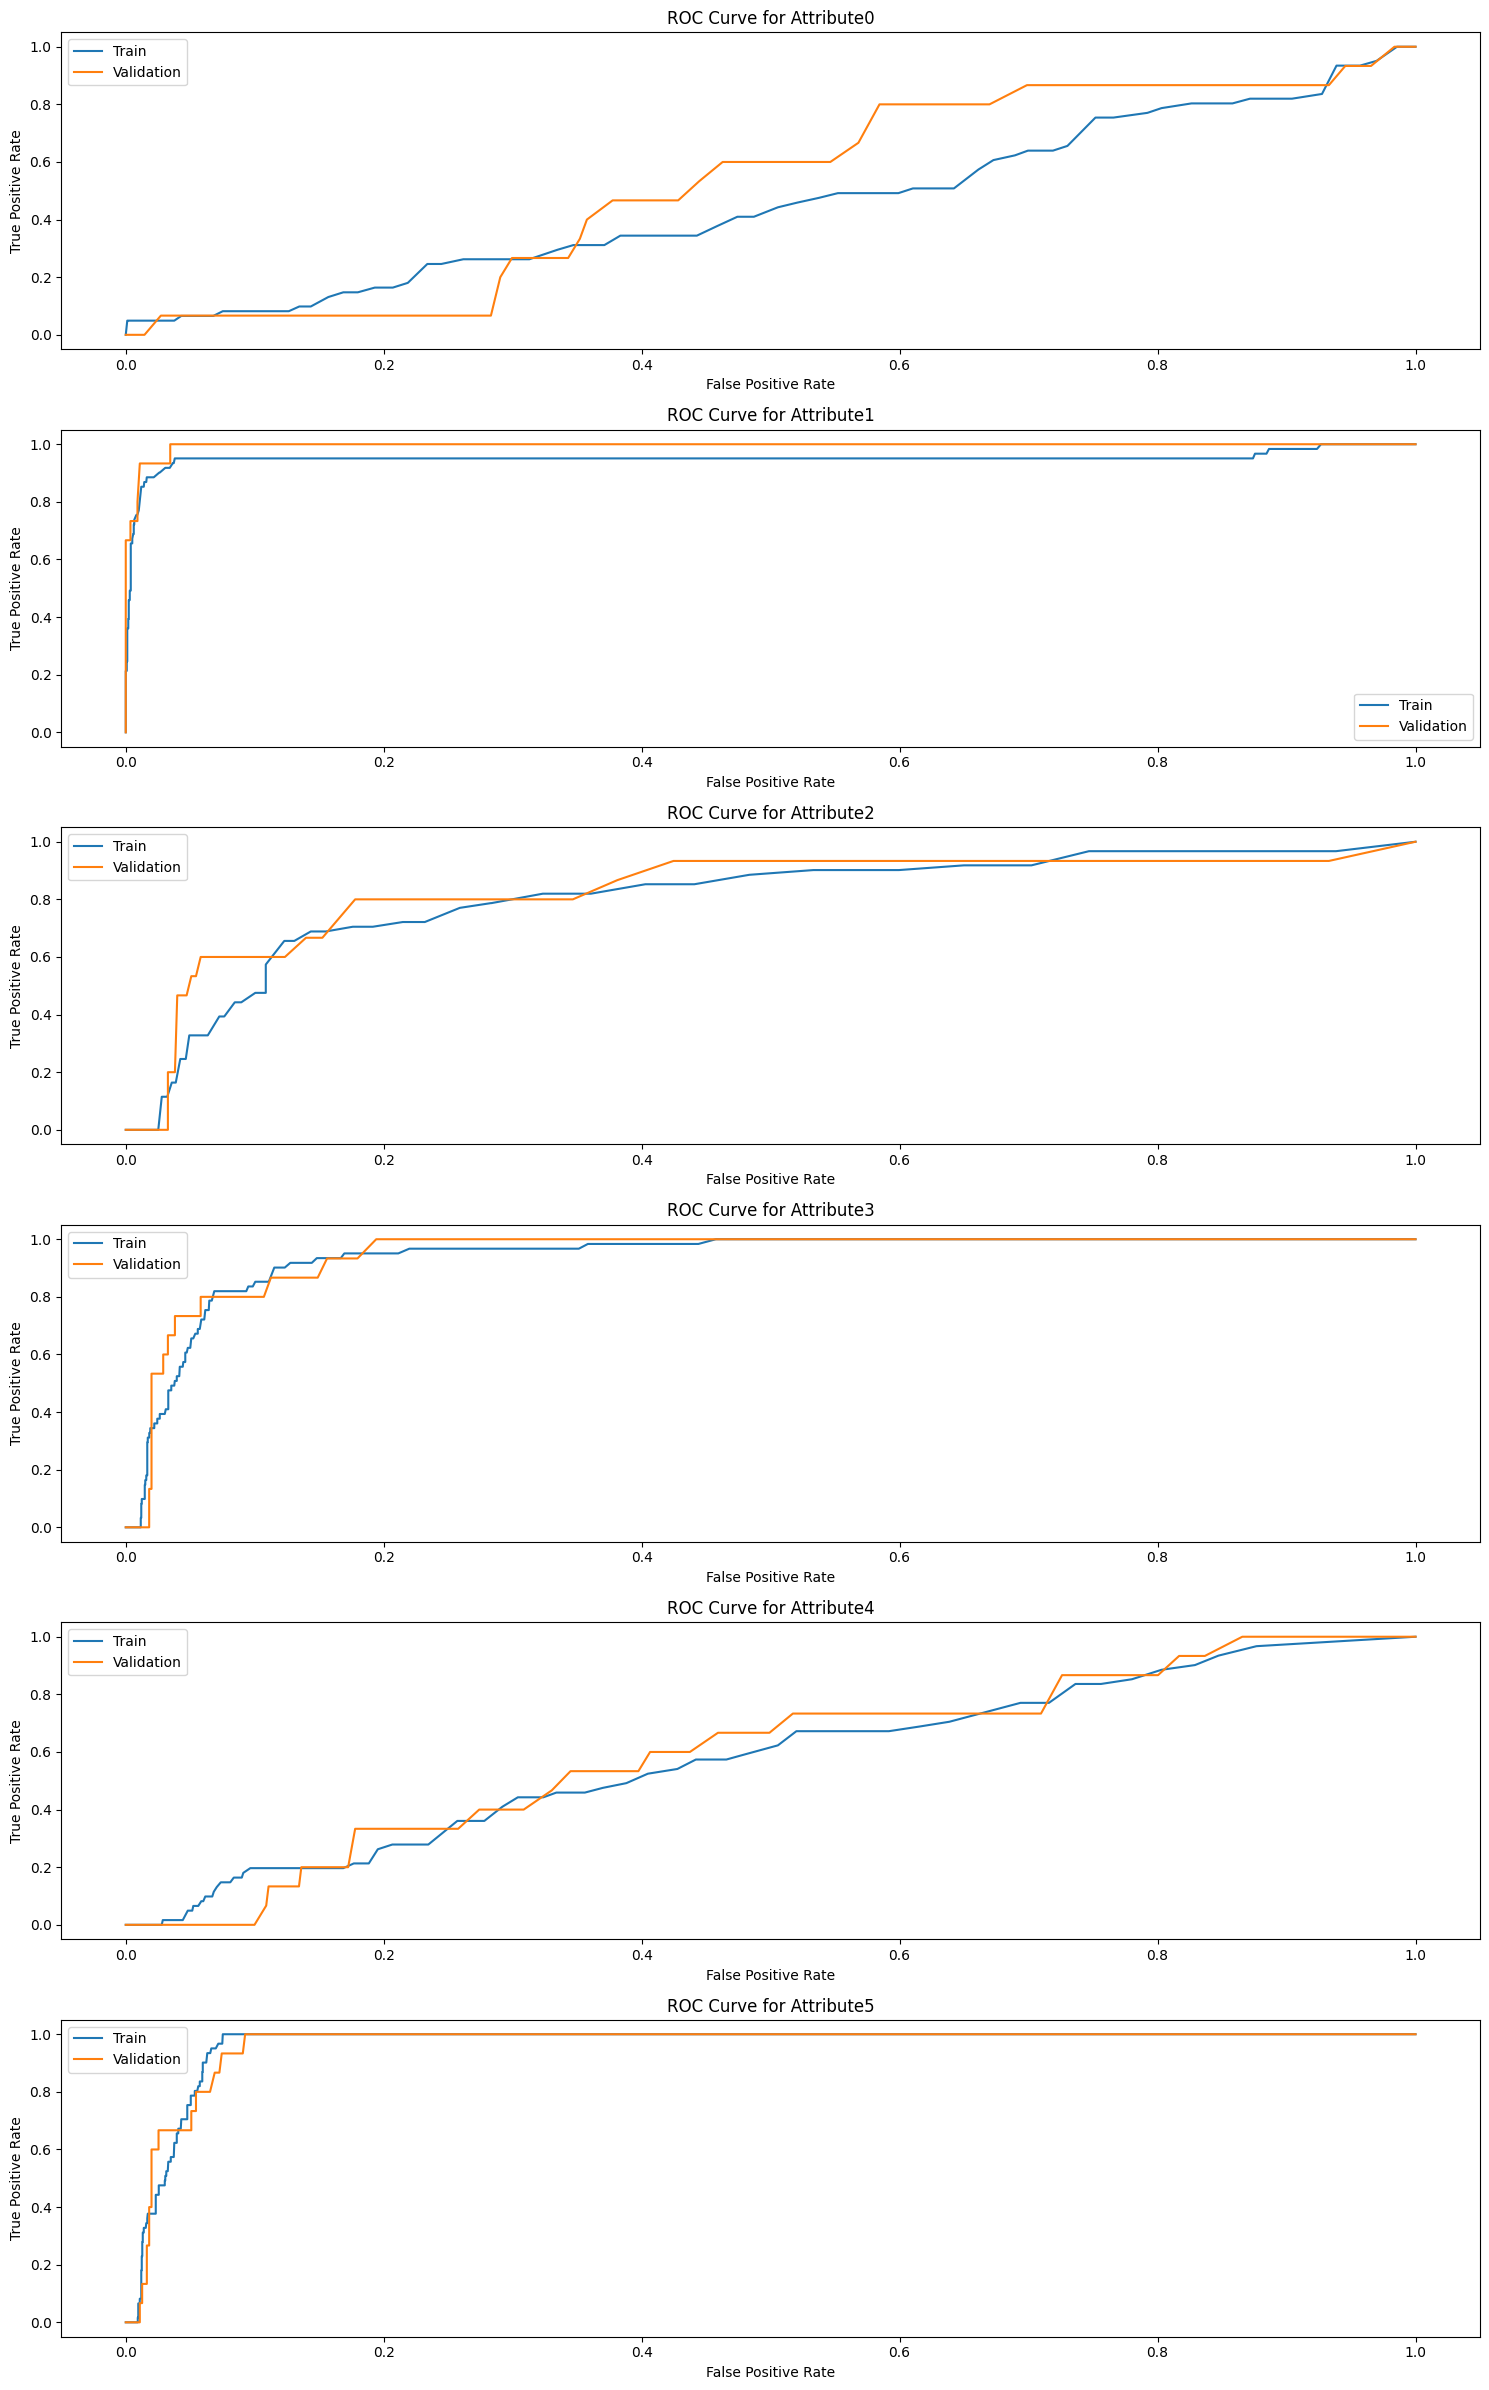

In [92]:
### YOUR CODE HERE ###
#referencing APS1070_Tutorial_Anomaly_Detection.ipynb code
### PART A: FITTING REGARDLESS OF CLASS ###
#Steps 1-3
#initial dataframe to easily store metrics (to be tabulated in the end)
output = pd.DataFrame(columns=['Feature', 'AUC_Train', 'AUC_Val'])
nplots=np.size(features)
plt.figure(figsize=(15,4*nplots))
gs = gridspec.GridSpec(nplots,1)
for i, feature in enumerate(features):
  gm = GaussianMixture(n_components=1, covariance_type = 'full', random_state=0)
  #fit single feature Gaussian distribution on train set
  gm.fit(X_train[[feature]])

  #compute log-likelihood scores of train/val datasets for each feature
  p_train = gm.score_samples(X_train[[feature]])
  p_val = gm.score_samples(X_val[[feature]])

  #ROC curves
  fpr_train, tpr_train, thresholds_train = roc_curve(y_train, -1*p_train)
  fpr_val, tpr_val, thresholds_val = roc_curve(y_val, -1*p_val)

  #append results to table, calculating the AUC
  output.loc[len(output.index)] = [feature, roc_auc_score(y_train, -1*p_train), roc_auc_score(y_val, -1*p_val)]

  #plot the ROC curves for each of the features
  ax = plt.subplot(gs[i])
  plt.plot(fpr_train, tpr_train, label='Train')
  plt.plot(fpr_val, tpr_val, label='Validation')
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('ROC Curve for ' + feature)
  plt.legend()

plt.tight_layout()
#print table
output


In [93]:
#Step 4: Find top 3 features based on AUC_val
output.sort_values(by='AUC_Val', ascending=False).head(3)

,Feature,AUC_Train,AUC_Val
1,Attribute1,0.950651,0.995523
5,Attribute5,0.967175,0.965638
3,Attribute3,0.940328,0.949123


In [94]:
#Make a prediction based on a model's scores: If the
#score_samples is lower than a threshold, we consider that
#patient as hypothyroid. Find an optimal threshold that maximizes
#the F1 Score of the validation set for each of those 3 features
#separately. (Do not check every possible value for threshold,
#come up with a faster way!) Compute F1 score using
#sklearn.metrics.f1_score. [0.5]

#Step 5: Find optimal threshold to maximize F1 Score --> using thresholds computed by ROC curve
top_3 = output.sort_values(by='AUC_Val', ascending=False).head(3)
results = pd.DataFrame(columns=['Feature', 'Optimal Threshold', 'F1_Score'])
for feature in top_3.Feature:
  gm3 = GaussianMixture(n_components=1, covariance_type = 'full', random_state=0)
  #Fit new Gaussian Mixture model for each of the top 3 features
  gm3.fit(X_train[[feature]])

  #Computer val_scores again for top 3 features
  p_val3 = gm3.score_samples(X_val[[feature]])

  #compute ROC curve
  fpr_val3, tpr_val3, thr_3 = roc_curve(y_val, -1*p_val3)

  #find optimal threshold value by iterating through the threshold array generated by the roc_curve function
  max_f1 = 0
  optimal_threshold = 0
  #print(len(thr_3))
  for threshold in thr_3:
    #predict labels based on threshold --> if p_val3 (score_samples) is less than a threshold, its considered hypothyroid
    f1 = f1_score(y_val, (p_val3 < threshold).astype(int))

    #track maximum f1 score resulting from optimal threshold. if f1 scores is greater than the previous - assign that as the new max.
    if f1 > max_f1:
      max_f1 = f1
      optimal_threshold = threshold
  #append results to output table
  results.loc[len(results.index)] = [feature, optimal_threshold, max_f1]

#print table
results

,Feature,Optimal Threshold,F1_Score
0,Attribute1,0.204371,0.800000
1,Attribute5,-1.576411,0.514286
2,Attribute3,-0.520173,0.468085


**Step 6: Calculating Complexity**
1. **Outer Loop:**
   - Iterates through the top 3 features
   - **Complexity:** O(3) simplifies to O(1)

2. **Fitting the Gaussian Mixture Model:**
   - This is done for one feature at a time, where n is the number of samples in the training set
   - **Complexity:** O(n)

3. **Scoring the Model:**
   - `p_val3 = gm3.score_samples(X_val[[feature]])` generates a score for each sample in the validation set, where m is the number of samples in the validation set and each score is assumed to be calculated in constant time
   - **Complexity:** O(m+1) = O(m)

4. **Computing ROC Curve:**
   - `roc_curve(y_val, -1*p_val3)` computes the false positive rate, true positive rate, and thresholds.
   - The number of thresholds depends on the number of unique score values in `p_val3`, but for the worst-case analysis, we can consider it proportional to m
   - **Complexity:** O(m)

5. **Threshold Search Loop:**
   - The loop iterates over each threshold in `thr_3` to compute the F1 Score
   - **Complexity:** O(m)
Note: all other assignments/comparison operators are O(1) so they were not included in this calculation

Combining all these components:
O(1) + O(n) + O(m) + O(m) + O(m) = O(n + m)

Therefore the complexity of determining the optimal threshold is O(n+m)






In [95]:
### PART B: FITTING BASED ON CLASS ###
#Step 1: Pick top 3 features with best AUC --> top_3 variable
#Step 2: Compute AUC and F1 Score when fitting a Gaussian only on not-hypothyroid patients (hypothyroid == 0)
X_train_not_hypo = X_train[y_train == 0]

results2 = pd.DataFrame(columns=['Feature', 'AUC_Train_b', 'AUC_Val_b', 'F1_Score_b'])

for feature in top_3.Feature:
  gm_class = GaussianMixture(n_components=1, covariance_type = 'full', random_state=0)
  #Fit new Gaussian Mixture model on not-hypothyroid class
  gm_class.fit(X_train_not_hypo[[feature]])

  #Computed scores again for top 3 features
  class_train_p = gm_class.score_samples(X_train[[feature]])
  class_val_p = gm_class.score_samples(X_val[[feature]])

  #compute ROC curve
  fpr_class_tr, tpr_class_tr, thr_class_tr = roc_curve(y_train, -1*class_train_p)
  fpr_class_val, tpr_class_val, thr_class_val = roc_curve(y_val, -1*class_val_p)

  best_f1 = 0
  best_threshold = 0

  for tr in thr_class_val:
    #predict labels based on threshold
    class_f1 = f1_score(y_val, (class_val_p < tr).astype(int))

    #track maximum f1 score resulting from optimal threshold. if f1 scores is greater than the previous - assign that as the new max.
    if class_f1 > best_f1:
      best_f1 = class_f1
      best_threshold = tr
  #append results to output table
  results2.loc[len(results2.index)] = [feature, roc_auc_score(y_train, -1*class_train_p), roc_auc_score(y_val, -1*class_val_p) , best_f1]

#print table
results2

,Feature,AUC_Train_b,AUC_Val_b,F1_Score_b
0,Attribute1,0.991473,0.995523,0.800000
1,Attribute5,0.970353,0.969873,0.512821
2,Attribute3,0.945490,0.953479,0.488889


In [96]:
#Step 3: Compare AUC and F1 Score Results from 2a and 2b in a table
table_a = top_3.join(results.set_index('Feature'), on='Feature')
table_a.drop(columns=['Optimal Threshold'], inplace=True)
compare = table_a.join(results2.set_index('Feature'), on='Feature')
compare

,Feature,AUC_Train,AUC_Val,F1_Score,AUC_Train_b,AUC_Val_b,F1_Score_b
1,Attribute1,0.950651,0.995523,0.800000,0.991473,0.995523,0.800000
5,Attribute5,0.967175,0.965638,0.514286,0.970353,0.969873,0.512821
3,Attribute3,0.940328,0.949123,0.468085,0.945490,0.953479,0.488889


**Step 4: Are these results similar/different? Why?**

Answer: The results are very similar to each other showing no apparent significant difference between the AUC scores and F1 scores between the
 model fitted regardless of class and the model fitted on the not-hypothyroid class alone. This is because the dataset is biased towards the not-hypothyroid class. Since there is far more not-hypothyroid data (97.5%) compared to the hypothyroid class (2.5%), this dominates when the model is fitted where the class is not specified, resulting in similar performance metrics in both cases.

## **Part 3: Multiple feature model with one Gaussian distribution: [1 Marks]**
This part is similar to Part 2, but we will pick multiple features and **visually** set the number of components of the GM model.

  a. 2D plot:
 1. Pick two features (say, Attribute1 and Attribute2).
 2. Scatter plot (plt.scatter) those features on a figure (Attribute1 on the x-axis and Attribute2 on the y-axis).
 3. Color the data points based on their class (not-hypothyroid blue and hypothyroid red).
 4. Based on your plots, decide how many Gaussian components (``n_components``) you need to fit the data (focus on not-hypothyroid patients). Explain.  **[0.25]**
 5. Fit your Gaussian model on all the data points.
 6. Compute AUC on both training and validation sets
 7. Pick 3 new pairs of features and repeat steps 2 to 6. **[0.25]**
 8. For each pair, find a threshold to maximize your validation set F1 Score.**[0.25]**
 9. For each pair, plot a figure similar to step 3 and put a circle around outliers based on your threshold (use the code of the similar figure in the tutorial) **[0.25]**





In [97]:
def computeGaussianPerformance(features, n_components, X_train, y_train, X_val, y_val):
  results = pd.DataFrame(columns=['Feature Pair', 'AUC_Train', 'AUC_Val', 'Best_Threshold', 'F1_Score'])
  gm = GaussianMixture(n_components=n_components, covariance_type = 'full', random_state=0)
  #fit new Gaussian Mixture model on not-hypothyroid class
  gm.fit(X_train[features])

  #compute scores for features
  train_p = gm.score_samples(X_train[features])
  val_p = gm.score_samples(X_val[features])

  #compute ROC curve - get threshold values
  fpr_tr, tpr_tr, thr_tr = roc_curve(y_train, -1*train_p)
  fpr_val, tpr_val, thr_val = roc_curve(y_val, -1*val_p)

  best_f1 = 0
  best_threshold = 0

  for tr in thr_val:
    #predict labels based on threshold
    f1 = f1_score(y_val, (val_p < tr).astype(int))
    #track maximum f1 score resulting from optimal threshold. if f1 scores is greater than the previous - assign that as the new max.
    if f1 > best_f1:
      best_f1 = f1
      best_threshold = tr
  #append results to output table
  results.loc[len(results.index)] = [features, roc_auc_score(y_train, -1*train_p), roc_auc_score(y_val, -1*val_p), best_threshold, best_f1]
  return results, val_p


In [99]:
#referencing Anomaly Detection Tutorial jupyter notebook - from piazza it says to plot using validation data
def anomalyPlot(features, features_ind, val_p, threshold, X_train, y_train, X_val, y_val):
  plt.figure(figsize=(8, 6))
  colours = {0:'blue', 1: 'red'}
  plt.scatter(X_val.iloc[:,features_ind[0]], X_val.iloc[:,features_ind[1]], marker='x', c=y_val.map(colours))
  outliers = np.nonzero((val_p < threshold))[0]
  plt.scatter(X_val.iloc[outliers, features_ind[0]], X_val.iloc[outliers,features_ind[1]], marker='o', facecolors='none', edgecolors='black', linewidths=2)
  plt.xlabel(features[0])
  plt.ylabel(features[1])
  plt.title('Outlier Detection of '+ features[0] + ' vs ' + features[1])
  plt.show()

##### **Attribute1 and Attribute2**

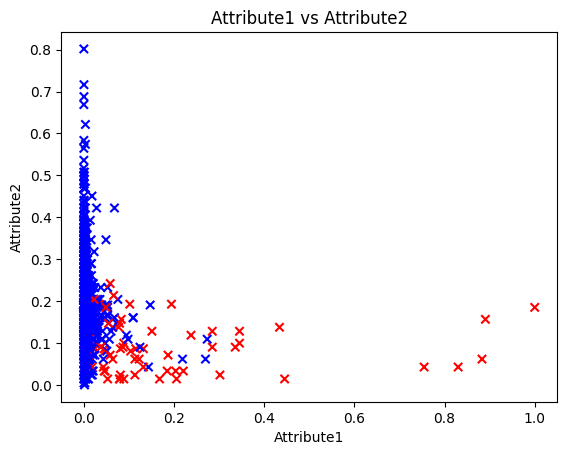

In [100]:
### YOUR CODE HERE ###
#Step 1-3: Select 2 features -> Attribute1 and Attribute2
colours = {0:'blue', 1: 'red'}
features = ['Attribute1','Attribute2']
columns = list(X_train.columns)
features_ind = [columns.index(feature) for feature in features]
plt.scatter(X_train[features[0]], X_train[features[1]], marker='x', c=y_train.map(colours))
plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title('Attribute1 vs Attribute2')
plt.show()

* **n_components: 1**
* **Reasoning: The blue (non-hypothyroid) class generally seems to fit a single cluster to the left of the graph which can be represented by a single Gaussian distribution.**

In [101]:
out, val_p = computeGaussianPerformance(features, 1, X_train, y_train, X_val, y_val)
out

,Feature Pair,AUC_Train,AUC_Val,Best_Threshold,F1_Score
0,"[Attribute1, Attribute2]",0.939791,0.933454,-3.798104,0.48


In [102]:
#try increasing n_components by 1:
out1, val_p1 = computeGaussianPerformance(features, 2, X_train, y_train, X_val, y_val)
out1

,Feature Pair,AUC_Train,AUC_Val,Best_Threshold,F1_Score
0,"[Attribute1, Attribute2]",0.976786,0.980278,-0.140068,0.571429


Although based on the graph a single Gaussian component appears to fit the data the best, it can be noted that by increasing it to 2 components, the F1 score improves by almost 0.1.

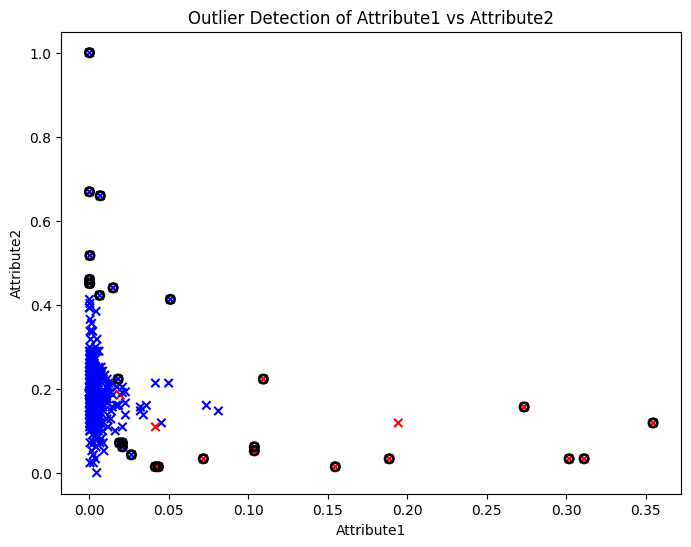

In [103]:
anomalyPlot(features, features_ind, val_p1, out1.Best_Threshold[0], X_train, y_train, X_val, y_val)

##### **Attribute2 and Attribute3**

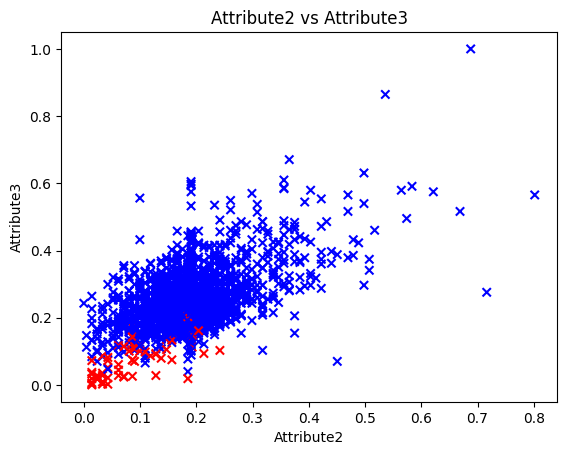

In [104]:
features1 = ['Attribute2','Attribute3']
features_ind1 = [columns.index(feature) for feature in features1]
plt.scatter(X_train[features1[0]], X_train[features1[1]], marker='x', c=y_train.map(colours))
plt.xlabel(features1[0])
plt.ylabel(features1[1])
plt.title('Attribute2 vs Attribute3')
plt.show()

* **n_components: 2**
* **Reasoning: The blue (non-hypothyroid) class generally seems to fit a single cluster to the bottom left of the graph but appear to be more spread out compared to the previous plot. Due to the wider spread, I think 2 components would be a good fit for the plot**

In [105]:
out2, val_p2 = computeGaussianPerformance(features1, 2, X_train, y_train, X_val, y_val)
out2

,Feature Pair,AUC_Train,AUC_Val,Best_Threshold,F1_Score
0,"[Attribute2, Attribute3]",0.910281,0.927889,-0.564474,0.409091


In [106]:
#increase components by 1 to see if there is an improvement
out3, val_p3 = computeGaussianPerformance(features1, 3, X_train, y_train, X_val, y_val)
out3

,Feature Pair,AUC_Train,AUC_Val,Best_Threshold,F1_Score
0,"[Attribute2, Attribute3]",0.893989,0.919177,-0.931027,0.428571


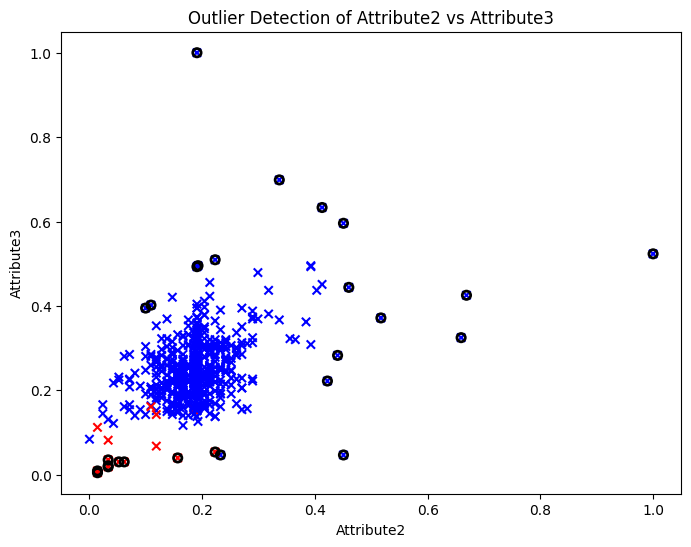

In [107]:
anomalyPlot(features1, features_ind1, val_p3, out3.Best_Threshold[0], X_train, y_train, X_val, y_val)

##### **Attribute0 and Attribute5**

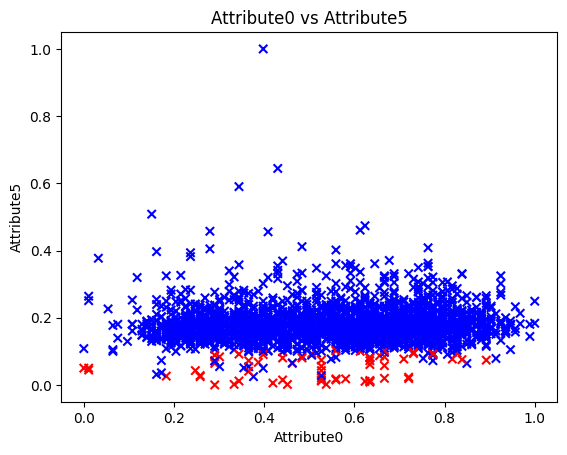

In [108]:
features2 = ['Attribute0','Attribute5']
features_ind2 = [columns.index(feature) for feature in features2]
plt.scatter(X_train[features2[0]], X_train[features2[1]], marker='x', c=y_train.map(colours))
plt.xlabel(features2[0])
plt.ylabel(features2[1])
plt.title('Attribute0 vs Attribute5')
plt.show()

* **n_components: 3**
* **Reasoning: The blue (non-hypothyroid) class generally seems to fit a single cluster in the middle of the graph but with significant spread across Attribute0. It looks like there are around 3-4 "peaks" in the graph - which could suggest that it may best be fitted to a combination of 3 Gaussian distributions that overlap.**

In [109]:
out4, val_p4 = computeGaussianPerformance(features2, 3, X_train, y_train, X_val, y_val)
out4

,Feature Pair,AUC_Train,AUC_Val,Best_Threshold,F1_Score
0,"[Attribute0, Attribute5]",0.961244,0.958863,-0.854456,0.487805


In [110]:
#try increasing by 1 to see if it improves
out5, val_p5 = computeGaussianPerformance(features2, 4, X_train, y_train, X_val, y_val)
out5

,Feature Pair,AUC_Train,AUC_Val,Best_Threshold,F1_Score
0,"[Attribute0, Attribute5]",0.963062,0.957169,-1.339361,0.514286


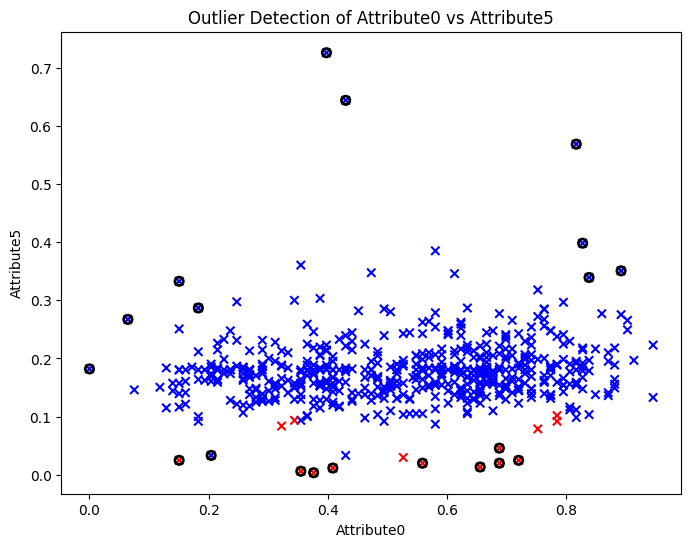

In [111]:
anomalyPlot(features2, features_ind2, val_p5, out5.Best_Threshold[0], X_train, y_train, X_val, y_val)

##### **Attribute2 and Attribute4**

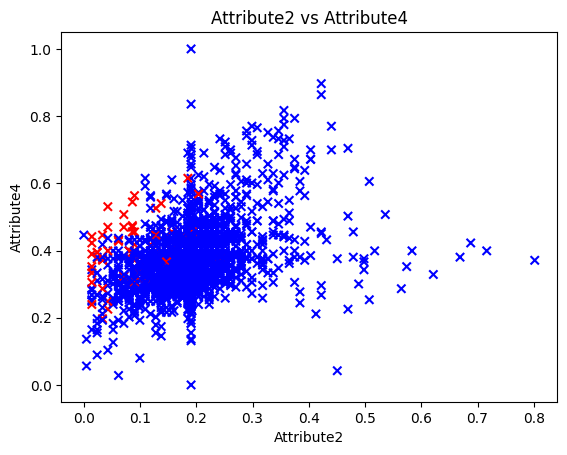

In [112]:
features3 = ['Attribute2','Attribute4']
features_ind3 = [columns.index(feature) for feature in features3]
plt.scatter(X_train[features3[0]], X_train[features3[1]], marker='x', c=y_train.map(colours))
plt.xlabel(features3[0])
plt.ylabel(features3[1])
plt.title('Attribute2 vs Attribute4')
plt.show()

* **n_components: 2**
* **Reasoning: The blue (non-hypothyroid) class generally seems to fit a single cluster to the left side of the graph, suggesting a single Gaussian component would best fit the data. As the data is more spreadout, 2 Gaussian distributions would likely account for the distribution across Attribute2**

In [113]:
out6, val_p6 = computeGaussianPerformance(features3, 2, X_train, y_train, X_val, y_val)
out6

,Feature Pair,AUC_Train,AUC_Val,Best_Threshold,F1_Score
0,"[Attribute2, Attribute4]",0.823426,0.884876,-0.527036,0.28


In [114]:
#try increasing by 1:
out7, val_p7 = computeGaussianPerformance(features3, 3, X_train, y_train, X_val, y_val)
out7

,Feature Pair,AUC_Train,AUC_Val,Best_Threshold,F1_Score
0,"[Attribute2, Attribute4]",0.813052,0.870236,0.50112,0.228571


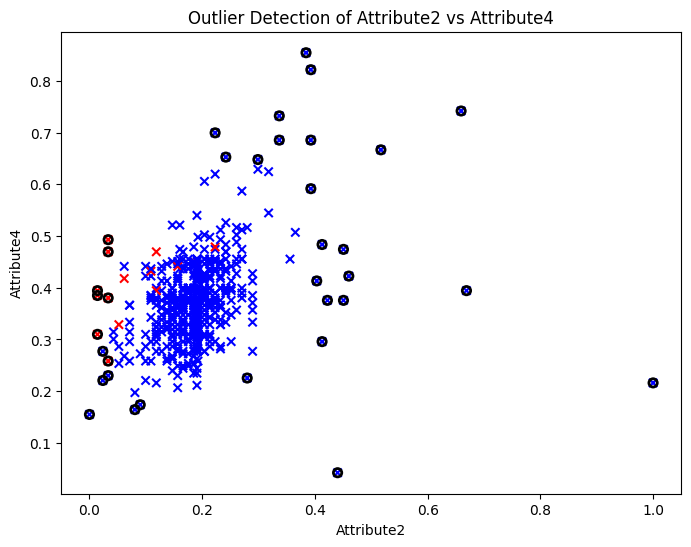

In [115]:
anomalyPlot(features3, features_ind3, val_p6, out6.Best_Threshold[0], X_train, y_train, X_val, y_val)

## **Part 4: Single feature model with two Gaussian distributions. [2 Marks]**
Now we will use two different distributions for hypothyroid and not-hypothyroid patients.
  1.  Fit a Gaussian distribution ($G_1$) on a feature of **not-hypothyroid patients** using ``sklearn.mixture.GaussianMixture`` when ``n_components=1``. **[0.25]**
  2. Fit another Gaussian distribution ($G_2$) on the same feature but for **hypothyroid patients** using ``sklearn.mixture.GaussianMixture`` when ``n_components=1``. **[0.25]**
  3. Compute the score samples ($S$) for both $G_1$ and $G_2$ on the **validation set** to get $S_1$ and $S_2$, respectively. **[0.25]**
  4. Find an optimal $c$ (a real number) that maximizes validation set F1 Score for a model such that if $S_1 < c \times S_2$, the patient is classified as hypothyroid. For example, if $c=1$ we could say that if $S_2$ is greater than $S_1$, ($S_1$<$S_2$) then the patient is hypothyroid (the patient belongs to the $G_2$ distribution which represents hypothyroid patients). For start consider $c$ in $[0,10]$ with steps of 0.1, you can change this window in your experiments if needed. **[0.25]**
  5. Repeat the steps above for all the features. What is the best F1 Score that you get for training and validation? Which feature and what c? **[1]**

In [116]:
### YOUR CODE HERE ###
#Step1&2: Fit a Gaussian distribution on a feature of not-hypothyroid and hypothyroid patients
X_train_not_hypo = X_train[y_train == 0]
X_train_hypo = X_train[y_train == 1]

best_f1_train = 0
best_f1_val = 0
best_c_train = 0
best_c_val = 0
best_feature_train = None
best_feature_val = None
for feature in X_train.columns:
  G1 = GaussianMixture(n_components=1, covariance_type = 'full', random_state=0)
  G2 = GaussianMixture(n_components=1, covariance_type = 'full', random_state=0)

  G1.fit(X_train_not_hypo[[feature]])
  G2.fit(X_train_hypo[[feature]])

  #Step3: Compute score samples for G1 and G2 for train & validation set
  S1_train = G1.score_samples(X_train[[feature]])
  S2_train = G2.score_samples(X_train[[feature]])
  S1_val = G1.score_samples(X_val[[feature]])
  S2_val = G2.score_samples(X_val[[feature]])

  #Step4: Find an optimal c that maximizes the validation set F1 score st S1 < c*S2
  for c in np.arange(0,10.1,0.1):
    #predict labels based on if S1 < c*S2 then its hypthyroid
    f1_train = f1_score(y_train, (S1_train < c*S2_train).astype(int))
    f1_val = f1_score(y_val, (S1_val < c*S2_val).astype(int))

    print("feature: ", feature, "c_val: ", c, " f1_train: ", f1_train, " f1_val: ", f1_val)

    #track best F1 score and 'c' value for training
    if f1_train > best_f1_train:
      best_f1_train = f1_train
      best_c_train = c
      best_feature_train = feature

    #track best F1 score and 'c' value for validation
    if f1_val > best_f1_val:
      best_f1_val = f1_val
      best_c_val = c
      best_feature_val = feature

#Step5: Best F1 score for training and validation, the feature and c value
print("Best Training F1 Score: ", best_f1_train)
print("Best c for Training: ", best_c_train)
print("Best Feature for Training: ", best_feature_train)

print("Best Validation F1 Score: ", best_f1_val)
print("Best c for Validation: ", best_c_val)
print("Best Feature for Validation: ", best_feature_val)

feature:  Attribute0 c_val:  0.0  f1_train:  0.038882138517618466  f1_val:  0.011627906976744186
feature:  Attribute0 c_val:  0.1  f1_train:  0.038882138517618466  f1_val:  0.011627906976744186
feature:  Attribute0 c_val:  0.2  f1_train:  0.04  f1_val:  0.023529411764705882
feature:  Attribute0 c_val:  0.30000000000000004  f1_train:  0.04  f1_val:  0.023529411764705882
feature:  Attribute0 c_val:  0.4  f1_train:  0.0422360248447205  f1_val:  0.023809523809523808
feature:  Attribute0 c_val:  0.5  f1_train:  0.04398447606727038  f1_val:  0.03821656050955414
feature:  Attribute0 c_val:  0.6000000000000001  f1_train:  0.042105263157894736  f1_val:  0.049079754601226995
feature:  Attribute0 c_val:  0.7000000000000001  f1_train:  0.044854881266490766  f1_val:  0.05952380952380952
feature:  Attribute0 c_val:  0.8  f1_train:  0.04529201430274136  f1_val:  0.058823529411764705
feature:  Attribute0 c_val:  0.9  f1_train:  0.047569803516028956  f1_val:  0.05286343612334802
feature:  Attribute0 c_

Step 5 Answer: Using the validation results, the best F1 score is 0.8. This corresponds to Attribute1 and a c value of 0. This implies that there is a strong separation between the classes which was noted in part 1, as the distribution for not-hypothyroid was very narrow and skewed all the way to the left side of the graph, whereas the hypothyroid class was very flat and distributed over a wider range. Also, as the dataset is imbalanced towards the not-hypothyroid class, the F1 score likely prioritizes the classification of this dominant class, and does not reqire a scaling 'c' to distinguish between the G1 and G2 scores.

## **Part 5: Multivariate and Mixture of Gaussians Distribution [4 Marks]**
We now want to build an outlier detection model that performs well in terms of F1 score. To design your model:

*   No restrictions on the number of features - use as few or as many as you want! (multivariate).
*   To fit your model, you can take advantage of the Gaussian mixture model, where you can set the number of components [help](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html).
*   You can choose to fit your Gaussians on not-hypothyroid patients or to both classes.


It is up to you how to design your model. Try at least 10 different models and report the AUC for both training and validation sets (if applicable) and the best F1 score for both training and validation sets for each model. What kind of model works better? How many features are best (and which ones)? How many Gaussians? How many components? Summarize your findings with tables or plots. **[4]**


**HINT !**

You might want to try a two-gaussian model, multiple features, a single component for the not-hypothyroid patient, and multiple components for hypothyroid ones! Why does it make sense to have multiple components for hypothyroid patients?

* **Model 1**: Fit on both classes all features, single component
* **Model 2**: Fit on both classes, top 3 features, single component
* **Model 3**: Fit on both classes - #1 Feature (Attribute1), sweep n_components from 1-10
* **Model 4**: Fit on non-hypothyroid, all features, single component
* **Model 5**: Fit on non-hypothyroid, top 3 features, single component
* **Model 6**: Fit on non-hypothyroid - #1 feature (Attribute1), sweep n_components
* **Model 7**: Fit on hypothyroid, all features, sweep n_components
* **Model 8**: 2 Gaussian, all features, single component
* **Model 9**: 2 Gaussian, top 3 features, single component
* **Model 10**: 2 Gaussian, #1 Feature (Attribute1), sweep n_components from 1-10


After the 10 models - I will compare them in a table and sort based on highest F1_score (on validation) and then by the AUC_val score. Since the goal is an outlier detection model that performs well in terms of F1 score, this will be prioritized. In the table, the top model will be selected. I will then see which hyperparameter (e.g., n_components, # of features) had the biggest impact on the F1 score and iterate the model on that.

In [117]:
### YOUR CODE HERE ###
def computeGaussianModelPerformance(model, features, n_components, X_train, y_train, X_val, y_val):
  results = pd.DataFrame(columns=['Features', 'AUC_Train', 'AUC_Val', 'Best_Threshold', 'F1_Score_train', 'F1_Score_val'])
  #fit new Gaussian Mixture model on not-hypothyroid class
  model.fit(X_train[features])

  #compute scores for features
  train_p = model.score_samples(X_train[features])
  val_p = model.score_samples(X_val[features])

  #compute ROC curve - get threshold values
  fpr_tr, tpr_tr, thr_tr = roc_curve(y_train, -1*train_p)
  fpr_val, tpr_val, thr_val = roc_curve(y_val, -1*val_p)

  best_f1_train = 0
  best_f1_val = 0
  best_threshold = 0

  for tr in thr_val:
    #predict labels based on threshold
    f1_train = f1_score(y_train, (train_p < tr).astype(int))
    f1_val = f1_score(y_val, (val_p < tr).astype(int))

    #track maximum f1 score resulting from optimal threshold. if f1 scores is greater than the previous - assign that as the new max.
    if f1_val > best_f1_val:
      best_f1_val = f1_val
      best_threshold = tr
    if f1_train > best_f1_train:
      best_f1_train = f1_train
  #append results to output table
  results.loc[len(results.index)] = [features, roc_auc_score(y_train, -1*train_p), roc_auc_score(y_val, -1*val_p), best_threshold, best_f1_train, best_f1_val]
  return results, val_p

In [118]:
def computeGaussianOnN(features, num_c, X_train, y_train, X_val, y_val):
    results = pd.DataFrame(columns=['Features', 'AUC_Train', 'AUC_Val', 'Best_Threshold', 'F1_Score_train', 'F1_Score_val', 'N_Components'])

    #sweep through n_components values
    for n in range(1, num_c):
        model = GaussianMixture(n_components=n, covariance_type='full', random_state=0)
        model.fit(X_train[features])

        #compute scores for features
        train_p = model.score_samples(X_train[features])
        val_p = model.score_samples(X_val[features])

        #compute ROC curve - get threshold values
        fpr_tr, tpr_tr, thr_tr = roc_curve(y_train, -1 * train_p)
        fpr_val, tpr_val, thr_val = roc_curve(y_val, -1 * val_p)

        #track best F1 score for this n
        best_f1_train = 0
        best_f1_val = 0
        best_threshold = 0

        #iterate through the thresholds and compute F1 score
        for tr in thr_val:
            f1_train = f1_score(y_train, (train_p < tr).astype(int))
            f1_val = f1_score(y_val, (val_p < tr).astype(int))

            #track maximum F1 score and corresponding threshold
            if f1_train > best_f1_train:
                best_f1_train = f1_train
            if f1_val > best_f1_val:
                best_f1_val = f1_val
                best_threshold = tr
        #append results to the DataFrame
        results.loc[len(results.index)] = [features, roc_auc_score(y_train, -1 * train_p), roc_auc_score(y_val, -1 * val_p), best_threshold, best_f1_train, best_f1_val, n]
    return results


In [35]:
#Model 1: Both classes, all features, n_components=1
model1 = GaussianMixture(n_components=1, covariance_type = 'full', random_state=0)
model1_output, _ = computeGaussianModelPerformance(model1, list(X_train.columns), 1, X_train, y_train, X_val, y_val)
model1_output

,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val
0,"[Attribute0, Attribute1, Attribute2, Attribute...",0.933079,0.942287,-4.594082,0.292683,0.285714


In [119]:
#Model 2: Both classes, top 3 features, n_components=1
model2 = GaussianMixture(n_components=1, covariance_type = 'full', random_state=0)
model2_output, _ = computeGaussianModelPerformance(model2, list(top_3.Feature), 1, X_train, y_train, X_val, y_val)
model2_output

,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val
0,"[Attribute1, Attribute5, Attribute3]",0.948747,0.951361,1.785605,0.347826,0.5


In [120]:
#Model 3: Fit on both classes - #1 Feature (Attribute1), sweep n_components from 1-10
model3_output = computeGaussianOnN(['Attribute1'], 11, X_train, y_train, X_val, y_val)
model3_output

,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val,N_Components
0,[Attribute1],0.950651,0.995523,0.204371,0.606061,0.800000,1
1,[Attribute1],0.971806,0.978463,-0.822284,0.424908,0.468750,2
2,[Attribute1],0.987201,0.991894,-2.369087,0.701987,0.800000,3
3,[Attribute1],0.987449,0.993708,-0.795759,0.683544,0.717949,4
4,[Attribute1],0.990360,0.995039,-1.296985,0.714286,0.800000,5
5,[Attribute1],0.990303,0.995039,-1.296985,0.714286,0.800000,6
6,[Attribute1],0.990608,0.994555,-1.917232,0.714286,0.800000,7
7,[Attribute1],0.990761,0.993708,-0.955258,0.713043,0.785714,8
8,[Attribute1],0.991218,0.995765,-0.922081,0.714286,0.785714,9
9,[Attribute1],0.991066,0.996007,-0.908572,0.720721,0.812500,10


In [121]:
model3_output = model3_output.sort_values(by=['F1_Score_val','AUC_Val'], ascending=False).head(1)
model3_output

,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val,N_Components
9,[Attribute1],0.991066,0.996007,-0.908572,0.720721,0.8125,10


In [122]:
X_train_not_hypo = X_train[y_train == 0]

def computeGaussianClass(model, features, n_components, X_class, X_train, y_train, X_val, y_val):
  results = pd.DataFrame(columns=['Features', 'AUC_Train', 'AUC_Val', 'F1_Score_train', 'F1_Score_val'])
  #fit new Gaussian Mixture model on not-hypothyroid class
  model.fit(X_class[features])

  train_p = model.score_samples(X_train[features])
  val_p = model.score_samples(X_val[features])

  #compute ROC curve
  fpr_tr, tpr_tr, thr_tr = roc_curve(y_train, -1*train_p)
  fpr_val, tpr_val, thr_val = roc_curve(y_val, -1*val_p)

  best_f1_train = 0
  best_f1_val = 0
  best_threshold = 0

  for tr in thr_val:
    #predict labels based on threshold
    f1_train = f1_score(y_train, (train_p < tr).astype(int))
    f1_val = f1_score(y_val, (val_p < tr).astype(int))

    #track maximum f1 score resulting from optimal threshold. if f1 scores is greater than the previous - assign that as the new max.
    if f1_train > best_f1_train:
      best_f1_train = f1_train
    if f1_val > best_f1_val:
      best_f1_val = f1_val
      best_threshold = tr
  #append results to output table
  results.loc[len(results.index)] = [features, roc_auc_score(y_train, -1*train_p), roc_auc_score(y_val, -1*val_p) , best_f1_train, best_f1_val]
  return results


In [123]:
#Model 4: Fit on not-hypothyroid, all features, single component
model4 = GaussianMixture(n_components=1, covariance_type = 'full', random_state=0)
model4_output = computeGaussianClass(model4, list(X_train.columns), 1, X_train_not_hypo, X_train, y_train, X_val, y_val)
model4_output

,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val
0,"[Attribute0, Attribute1, Attribute2, Attribute...",0.977873,0.976407,0.571429,0.625


In [124]:
#Model 5: Fit on not-hypothyroid, top 3 features, single component
model5 = GaussianMixture(n_components=1, covariance_type = 'full', random_state=0)
model5_output = computeGaussianClass(model5, list(top_3.Feature), 1, X_train_not_hypo, X_train, y_train, X_val, y_val)
model5_output

,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val
0,"[Attribute1, Attribute5, Attribute3]",0.980899,0.983787,0.634921,0.666667


In [125]:
def computeGaussianOnNClass(features, num_c, X_class, X_train, y_train, X_val, y_val):
    results = pd.DataFrame(columns=['Features', 'AUC_Train', 'AUC_Val', 'Best_Threshold', 'F1_Score_train', 'F1_Score_val', 'N_Components'])

    #sweep through n_components values
    for n in range(1, num_c):
        model = GaussianMixture(n_components=n, covariance_type='full', random_state=0)
        model.fit(X_class[features])

        #compute scores for features
        train_p = model.score_samples(X_train[features])
        val_p = model.score_samples(X_val[features])

        #compute ROC curve - get threshold values
        fpr_tr, tpr_tr, thr_tr = roc_curve(y_train, -1 * train_p)
        fpr_val, tpr_val, thr_val = roc_curve(y_val, -1 * val_p)

        #track best F1 score for this n
        best_f1_train = 0
        best_f1_val = 0
        best_threshold = 0

        #iterate through the thresholds and compute F1 score
        for tr in thr_val:
            f1_train = f1_score(y_train, (train_p < tr).astype(int))
            f1_val = f1_score(y_val, (val_p < tr).astype(int))

            #track maximum F1 score and corresponding threshold for val
            if f1_train > best_f1_train:
                best_f1_train = f1_train
            if f1_val > best_f1_val:
                best_f1_val = f1_val
                best_threshold = tr

        #append results to the DataFrame
        results.loc[len(results.index)] = [features, roc_auc_score(y_train, -1 * train_p), roc_auc_score(y_val, -1 * val_p), best_threshold, best_f1_train, best_f1_val, n]
    return results


In [126]:
#Model 6:  Fit on non-hypothyroid - #1 feature (Attribute1), sweep n_components
model6_output = computeGaussianOnNClass(['Attribute1'], 11, X_train_not_hypo, X_train, y_train, X_val, y_val)
model6_output

,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val,N_Components
0,[Attribute1],0.991473,0.995523,-0.738299,0.722222,0.800000,1
1,[Attribute1],0.990615,0.995039,-0.001469,0.722222,0.800000,2
2,[Attribute1],0.989858,0.996612,-1.887021,0.688312,0.777778,3
3,[Attribute1],0.991257,0.995039,-3.683680,0.731707,0.800000,4
4,[Attribute1],0.991447,0.993708,-0.948310,0.721311,0.785714,5
5,[Attribute1],0.991517,0.993587,-1.143463,0.727273,0.785714,6
6,[Attribute1],0.991644,0.995765,-1.843714,0.714286,0.785714,7
7,[Attribute1],0.991829,0.994797,-1.704456,0.727273,0.785714,8
8,[Attribute1],0.992147,0.994676,-0.871366,0.727273,0.800000,9
9,[Attribute1],0.991975,0.995644,-0.868473,0.730435,0.848485,10


In [127]:
model6_output = model6_output.sort_values(by=['F1_Score_val','AUC_Val'], ascending=False).head(1)
model6_output

,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val,N_Components
9,[Attribute1],0.991975,0.995644,-0.868473,0.730435,0.848485,10


In [128]:
# Model 7: Fit on hypothyroid, all features, sweep n_components (of all data)
X_train_hypo = X_train[y_train == 1]
model7_output = computeGaussianOnNClass(list(X_train.columns), len(X_train_hypo), X_train_hypo, X_train, y_train, X_val, y_val)
model7_output

,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val,N_Components
0,"[Attribute0, Attribute1, Attribute2, Attribute...",0.055537,0.032184,inf,0.045168,0.051635,1
1,"[Attribute0, Attribute1, Attribute2, Attribute...",0.049098,0.071506,inf,0.045168,0.051635,2
2,"[Attribute0, Attribute1, Attribute2, Attribute...",0.006865,0.010889,inf,0.045168,0.051635,3
3,"[Attribute0, Attribute1, Attribute2, Attribute...",0.014372,0.044162,inf,0.045168,0.051635,4
4,"[Attribute0, Attribute1, Attribute2, Attribute...",0.003560,0.031095,inf,0.045168,0.051635,5
5,"[Attribute0, Attribute1, Attribute2, Attribute...",0.003560,0.031095,inf,0.045168,0.051635,6
6,"[Attribute0, Attribute1, Attribute2, Attribute...",0.003382,0.045735,inf,0.045168,0.051635,7
7,"[Attribute0, Attribute1, Attribute2, Attribute...",0.003197,0.068724,inf,0.045168,0.051635,8
8,"[Attribute0, Attribute1, Attribute2, Attribute...",0.002536,0.100060,inf,0.045168,0.051635,9
9,"[Attribute0, Attribute1, Attribute2, Attribute...",0.000095,0.030006,inf,0.045168,0.051635,10


In [129]:
model7_output = model7_output.sort_values(by=['F1_Score_val','AUC_Val'], ascending=False).head(1)
model7_output

,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val,N_Components
19,"[Attribute0, Attribute1, Attribute2, Attribute...",0.000013,0.112402,1.948581,0.045168,0.052083,20


Fitting the data only on the hypothyroid class showed very poor results overall no matter how many components were used. This is likely attributed to the imbalanced dataset. There is not enough data in the hypothyroid class for the model to properly generalize on unseen data.

In [131]:
def twoGaussian(features, num_c, X_train, y_train, X_val, y_val):
  results = pd.DataFrame(columns=['Features', 'AUC_Train', 'AUC_Val', 'F1_Score_train', 'F1_Score_val', 'Best_c'])
  #Step1&2: Fit a Gaussian distribution on a feature of not-hypothyroid and hypothyroid patients
  X_train_not_hypo = X_train[y_train == 0]
  X_train_hypo = X_train[y_train == 1]

  best_f1_train = 0
  best_f1_val = 0
  best_c_val = 0

  G1 = GaussianMixture(n_components=num_c, covariance_type = 'full', random_state=0)
  G2 = GaussianMixture(n_components=num_c, covariance_type = 'full', random_state=0)

  G1.fit(X_train_not_hypo[features])
  G2.fit(X_train_hypo[features])

  S1_train = G1.score_samples(X_train[features])
  S2_train = G2.score_samples(X_train[features])

  S1 = G1.score_samples(X_val[features])
  S2 = G2.score_samples(X_val[features])

  for c in np.arange(0,10.1,0.1):
    #predict labels based on if S1 < c*S2 then its hypthyroid
    f1_train = f1_score(y_train, (S1_train < c*S2_train).astype(int))
    f1_val = f1_score(y_val, (S1 < c*S2).astype(int))

    #track best F1 score and 'c' value for validation
    if f1_val > best_f1_val:
      best_f1_val = f1_val
      best_c_val = c
    if f1_train > best_f1_train:
      best_f1_train = f1_train
  #computing 'relative' AUC scores by subtracting S1 from S2
  results.loc[len(results.index)] = [features, roc_auc_score(y_train, -1*(S1_train-S2_train)), roc_auc_score(y_val, -1*(S1-S2)), best_f1_train, best_f1_val, best_c_val]
  return results

In [132]:
# Model 8: 2 Gaussian, all features, single component
model8_output = twoGaussian(list(X_train.columns), 1, X_train, y_train, X_val, y_val)
model8_output

,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val,Best_c
0,"[Attribute0, Attribute1, Attribute2, Attribute...",0.995868,0.998306,0.785714,0.875,0.7


In [133]:
# Model 9: 2 Gaussian, top 3 features, single component
model9_output = twoGaussian(list(top_3.Feature), 1, X_train, y_train, X_val, y_val)
model9_output

,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val,Best_c
0,"[Attribute1, Attribute5, Attribute3]",0.993415,0.99758,0.740741,0.83871,0.4


In [134]:
def twoGaussianN(features, num_c, X_train, y_train, X_val, y_val):
    results = pd.DataFrame(columns=['Features', 'AUC_Train', 'AUC_Val', 'F1_Score_train', 'F1_Score_val', 'N_Components_G1', 'N_Components_G2','Best_c'])

    #Step1&2: Fit a Gaussian distribution on a feature of not-hypothyroid and hypothyroid patients
    X_train_not_hypo = X_train[y_train == 0]
    X_train_hypo = X_train[y_train == 1]

    #sweep through n_components values
    for n1 in range(1, num_c):
      for n2 in range(1, num_c):
        G1 = GaussianMixture(n_components=n1, covariance_type='full', random_state=0)
        G2 = GaussianMixture(n_components=n2, covariance_type='full', random_state=0)

        G1.fit(X_train_not_hypo[features])
        G2.fit(X_train_hypo[features])

        S1_train = G1.score_samples(X_train[features])
        S2_train = G2.score_samples(X_train[features])

        S1 = G1.score_samples(X_val[features])
        S2 = G2.score_samples(X_val[features])

        #track best F1 scores for this n
        best_f1_train = 0
        best_f1_val = 0
        best_c_val = 0

        for c in np.arange(0, 10.1, 0.1):
            #predict labels based on if S1 < c*S2 then it's hypothyroid
            f1_train = f1_score(y_train, (S1_train < c*S2_train).astype(int))
            f1_val = f1_score(y_val, (S1 < c*S2).astype(int))

            #track best F1 scores and 'c' values (best c comes from f1_val)
            if f1_val > best_f1_val:
                best_f1_val = f1_val
                best_c_val = c
            if f1_train > best_f1_train:
                best_f1_train = f1_train

        #append results to the DataFrame
        results.loc[len(results.index)] = [features, roc_auc_score(y_train, -1 * (S1_train - S2_train)), roc_auc_score(y_val, -1 * (S1 - S2)), best_f1_train, best_f1_val, n1, n2, best_c_val]
    return results


In [135]:
# Model 10: 2 Gaussian, #1 Feature (Attribute1), sweep n_components from 1-10
model10_output = twoGaussianN(['Attribute1'], 11, X_train, y_train, X_val, y_val)
model10_output

,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val,N_Components_G1,N_Components_G2,Best_c
0,[Attribute1],0.991473,0.995523,0.701987,0.800000,1,1,0.0
1,[Attribute1],0.991473,0.995523,0.701987,0.800000,1,2,0.0
2,[Attribute1],0.991473,0.995523,0.701987,0.800000,1,3,0.0
3,[Attribute1],0.991473,0.995523,0.701987,0.800000,1,4,0.0
4,[Attribute1],0.991473,0.995523,0.701987,0.800000,1,5,0.0
...,...,...,...,...,...,...,...,...
95,[Attribute1],0.992108,0.995160,0.642857,0.717949,10,6,0.0
96,[Attribute1],0.992108,0.995160,0.642857,0.717949,10,7,0.0
97,[Attribute1],0.992045,0.994918,0.642857,0.717949,10,8,0.0
98,[Attribute1],0.992045,0.994918,0.642857,0.717949,10,9,0.0


In [136]:
model10_output = model10_output.sort_values(by=['F1_Score_val','AUC_Val'], ascending=False).head(1)
model10_output

,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val,N_Components_G1,N_Components_G2,Best_c
9,[Attribute1],0.9916,0.996612,0.701987,0.8,1,10,0.0


**Summary of 10 Models**


In [138]:
#initialize empty DataFrame to collect results
summary = pd.DataFrame()

#loop through each model{i}_output dataframe, adding a new column called Model_Name with its value
for i in range(1,11):
  curr_model = globals()['model'+str(i)+'_output'] #https://www.geeksforgeeks.org/python-globals-function/
  curr_model['Model_Name'] = 'Model '+str(i)
  curr_model = curr_model[['Model_Name'] + [col for col in curr_model.columns if col != 'Model_Name']] #rearrange columns to put 'Model_Name' first
  summary = pd.concat([summary, curr_model], ignore_index=True) #append current model_output to the summary dataframe
summary

,Model_Name,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val,N_Components,Best_c,N_Components_G1,N_Components_G2
0,Model 1,"[Attribute0, Attribute1, Attribute2, Attribute...",0.933079,0.942287,-4.594082,0.292683,0.285714,NaN,NaN,NaN,NaN
1,Model 2,"[Attribute1, Attribute5, Attribute3]",0.948747,0.951361,1.785605,0.347826,0.500000,NaN,NaN,NaN,NaN
2,Model 3,[Attribute1],0.991066,0.996007,-0.908572,0.720721,0.812500,10.0,NaN,NaN,NaN
3,Model 4,"[Attribute0, Attribute1, Attribute2, Attribute...",0.977873,0.976407,NaN,0.571429,0.625000,NaN,NaN,NaN,NaN
4,Model 5,"[Attribute1, Attribute5, Attribute3]",0.980899,0.983787,NaN,0.634921,0.666667,NaN,NaN,NaN,NaN
5,Model 6,[Attribute1],0.991975,0.995644,-0.868473,0.730435,0.848485,10.0,NaN,NaN,NaN
6,Model 7,"[Attribute0, Attribute1, Attribute2, Attribute...",0.000013,0.112402,1.948581,0.045168,0.052083,20.0,NaN,NaN,NaN
7,Model 8,"[Attribute0, Attribute1, Attribute2, Attribute...",0.995868,0.998306,NaN,0.785714,0.875000,NaN,0.7,NaN,NaN
8,Model 9,"[Attribute1, Attribute5, Attribute3]",0.993415,0.997580,NaN,0.740741,0.838710,NaN,0.4,NaN,NaN
9,Model 10,[Attribute1],0.991600,0.996612,NaN,0.701987,0.800000,NaN,0.0,1.0,10.0


In [139]:
summary.sort_values(by=['F1_Score_val','AUC_Val'], ascending=False).head(3)

,Model_Name,Features,AUC_Train,AUC_Val,Best_Threshold,F1_Score_train,F1_Score_val,N_Components,Best_c,N_Components_G1,N_Components_G2
7,Model 8,"[Attribute0, Attribute1, Attribute2, Attribute...",0.995868,0.998306,NaN,0.785714,0.875000,NaN,0.7,NaN,NaN
5,Model 6,[Attribute1],0.991975,0.995644,-0.868473,0.730435,0.848485,10.0,NaN,NaN,NaN
8,Model 9,"[Attribute1, Attribute5, Attribute3]",0.993415,0.997580,NaN,0.740741,0.838710,NaN,0.4,NaN,NaN


The best model was identified as Model 8: 2 Gaussian, all features, single component. The next best model was iterated from 1-10 n_components. To see if this will improve the F1 score of Model 8, I will also iterate both Gaussians by 1-5 components to see if the F1 score improves.

In [141]:
# Model 11: 2 Gaussian, all features, sweep n_components 1-5
model11_output = twoGaussianN(list(X_train.columns), 6, X_train, y_train, X_val, y_val)
model11_output

,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val,N_Components_G1,N_Components_G2,Best_c
0,"[Attribute0, Attribute1, Attribute2, Attribute...",0.995868,0.998306,0.785714,0.875000,1,1,0.7
1,"[Attribute0, Attribute1, Attribute2, Attribute...",0.995868,0.998185,0.773723,0.875000,1,2,0.7
2,"[Attribute0, Attribute1, Attribute2, Attribute...",0.997121,0.998669,0.820896,0.875000,1,3,0.6
3,"[Attribute0, Attribute1, Attribute2, Attribute...",0.996415,0.998427,0.802920,0.875000,1,4,0.5
4,"[Attribute0, Attribute1, Attribute2, Attribute...",0.997413,0.998669,0.829630,0.875000,1,5,0.6
5,"[Attribute0, Attribute1, Attribute2, Attribute...",0.997006,0.999395,0.842857,0.882353,2,1,0.7
6,"[Attribute0, Attribute1, Attribute2, Attribute...",0.996987,0.999395,0.834532,0.882353,2,2,0.6
7,"[Attribute0, Attribute1, Attribute2, Attribute...",0.997667,0.999758,0.869565,0.937500,2,3,0.6
8,"[Attribute0, Attribute1, Attribute2, Attribute...",0.997426,0.999516,0.840580,0.937500,2,4,0.5
9,"[Attribute0, Attribute1, Attribute2, Attribute...",0.997820,0.999758,0.859259,0.937500,2,5,0.5


In [142]:
model11_output = model11_output.sort_values(by=['F1_Score_val','AUC_Val'], ascending=False).head(1)
model11_output

,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val,N_Components_G1,N_Components_G2,Best_c
22,"[Attribute0, Attribute1, Attribute2, Attribute...",0.998627,0.999637,0.880597,0.965517,5,3,0.7


We can see now that both the relative AUC_val score and F1_Score have  improved with a number of 5 components on the Gaussian fitted to the not-hypothyroid class and 3 components on the Gaussian fitted to the hypothyroid class. This demonstrates that the model has reasonable complexity. However, it should be noted that the discrepency between F1 scores suggest that the model may be overfitting. To prevent this, I will see if fitting the model on a decreasing amount of features (dropping features until the #1 is reached) will improve this.

In [143]:
feature_order = output.sort_values(by=['AUC_Val'], ascending=False)
feature_list = list(feature_order.Feature)

In [144]:
def twoGaussian(features, X_train, y_train, X_val, y_val):
    results = pd.DataFrame(columns=['Features', 'AUC_Train', 'AUC_Val', 'F1_Score_train', 'F1_Score_val', 'Best_c'])

    #Step1&2: Fit a Gaussian distribution on a feature of not-hypothyroid and hypothyroid patients
    X_train_not_hypo = X_train[y_train == 0]
    X_train_hypo = X_train[y_train == 1]

    best_f1_train = 0
    best_f1_val = 0
    best_c_val = 0

    G1 = GaussianMixture(n_components=5, covariance_type='full', random_state=0)
    G2 = GaussianMixture(n_components=3, covariance_type='full', random_state=0)

    G1.fit(X_train_not_hypo[features])
    G2.fit(X_train_hypo[features])

    S1_train = G1.score_samples(X_train[features])
    S2_train = G2.score_samples(X_train[features])

    S1 = G1.score_samples(X_val[features])
    S2 = G2.score_samples(X_val[features])

    for c in np.arange(0, 10.1, 0.1):
        #predict labels based on if S1 < c*S2, then it's hypothyroid
        f1_train = f1_score(y_train, (S1_train < c*S2_train).astype(int))
        f1_val = f1_score(y_val, (S1 < c*S2).astype(int))

        #track best F1 score and 'c' value for validation
        if f1_val > best_f1_val:
            best_f1_val = f1_val
            best_c_val = c
        if f1_train > best_f1_train:
            best_f1_train = f1_train

    #compute 'relative' AUC scores by subtracting S1 from S2
    results.loc[len(results.index)] = [features, roc_auc_score(y_train, -1 * (S1_train - S2_train)), roc_auc_score(y_val, -1 * (S1 - S2)), best_f1_train, best_f1_val, best_c_val]
    return results

#initialize an empty DataFrame to collect results from each iteration
all_results = pd.DataFrame()

for i in range(1, len(feature_list) + 1):
    model_output = twoGaussian(feature_list[:i], X_train, y_train, X_val, y_val) #use up to the ith index of the array
    all_results = pd.concat([all_results, model_output], ignore_index=True)
all_results


,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val,Best_c
0,[Attribute1],0.991943,0.994313,0.631579,0.700000,0.0
1,"[Attribute1, Attribute5]",0.998449,1.000000,0.897059,0.967742,0.4
2,"[Attribute1, Attribute5, Attribute3]",0.999104,0.998790,0.885246,0.866667,0.4
3,"[Attribute1, Attribute5, Attribute3, Attribute2]",0.999447,0.997096,0.906250,0.928571,0.5
4,"[Attribute1, Attribute5, Attribute3, Attribute...",0.998335,0.997459,0.869565,0.928571,0.5
5,"[Attribute1, Attribute5, Attribute3, Attribute...",0.998627,0.999637,0.880597,0.965517,0.7


In [145]:
model12_output = all_results.sort_values(by=['F1_Score_val','AUC_Val'], ascending=False).head(1)
model12_output

,Features,AUC_Train,AUC_Val,F1_Score_train,F1_Score_val,Best_c
1,"[Attribute1, Attribute5]",0.998449,1.0,0.897059,0.967742,0.4


Seeing that the simpler model (one with the top 2 features) has very close AUC scores on the train and validation, suggests that the model is generalizing well to unseen data. The significant difference between the F1 scores, where the validation score is higher than the training score, indicates that the model may be effectively capturing the essential patterns in the validation set, potentially due to its lower complexity and reduced risk of overfitting. As such, this will be used as the best model.

## **Part 6: Evaluating performance on test set: [1 Mark]**
**Which model worked better?** Pick your best model among all models and apply it to your test set. Report the F1 Score, Precision and Recall on the test set. **[1]**


Best Model: 2 Gaussian - G1 fitted on not-hypothyroid class with 5 components and G2 fitted on hypothyroid class with 3 components on Attribute1 and Attribute5 with a c=0.4.

In [146]:
### YOUR CODE HERE ###
from sklearn.metrics import precision_score, recall_score
X_train_not_hypo = X_train[y_train == 0]
X_train_hypo = X_train[y_train == 1]

#create 2 Gaussian models -> G1 with 5 components and G2 with 3 components
G1 = GaussianMixture(n_components=5, covariance_type = 'full', random_state=0)
G2 = GaussianMixture(n_components=3, covariance_type = 'full', random_state=0)

final_features = ['Attribute1', 'Attribute5']
#fit G1 to not-hypothyroid class and G2 to hypothyroid class of all features
G1.fit(X_train_not_hypo[final_features])
G2.fit(X_train_hypo[final_features])

#compute scores on test set
S1 = G1.score_samples(X_test[final_features])
S2 = G2.score_samples(X_test[final_features])

#threshold constant
c = 0.4

#predict labels based on if S1 < c*S2 then its hypthyroid
predicted_labels = (S1 < c*S2).astype(int)

#compute metrics
f1 = f1_score(y_test, predicted_labels)
precision = precision_score(y_test, predicted_labels)
recall = recall_score(y_test, predicted_labels)

print("F1 Score: ", f1)
print("Precision: ", precision)
print("Recall: ", recall)



F1 Score:  0.9444444444444444
Precision:  0.8947368421052632
Recall:  1.0


The F1 score of 0.944 suggests a good balance between precision and recall, reflecting the models ability to detect positive cases of hypothyroidism. The precision score of 0.895 indicates that when the model predicts a patient as hypothyroid, it is correct approximately 89.5% of the time, showcasing a relatively low number of false positives. Moreover, achieving a perfect recall of 1.0 means the model correctly identifies all actual positive cases in the test set, which is important given the potential health implications of missing a hypothyroid case. Overall, these results suggest that the model not only demonstrates sensitivity in detecting hypothyroid cases but also maintains a good level of accuracy.

## **Part 7: Is Gaussian the only useful distribution? [1 Mark]**

Search for other distributions that could be used to model the data. How popular are they? Is there a specific situation where a distribution works better? How can we find a suitable distribution to model our data? Do not forget to include your references.


The task for this project was to classify whether a data sample was hypothyroid or non-hypothyroid. Other distributions that could also be used to model the data in this type of problem (binary classification) are the following:


1.   Bernoulli Distribution
2.   Binomial Distribution
3.   Logistic Distribution

**Bernoulli Distribution**


*   Common distribution for binary classification tasks (https://machinelearningmastery.com/types-of-classification-in-machine-learning/)
*   This distribution is a discrete probability distribution where there are only 2 distinct outcomes: success/failure, true/false, etc. (https://reason.town/data-distribution-in-machine-learning/#The_Bernoulli_Distribution)
*   It only considers the probability of a single trail/individual event
*   Often considered a special case of binomial distribution
*   Example: Testing a single patient (data sample) for hypothyroidism

**Binomial Distribution**
*   Also a probability distribution with two different outcomes
*   Commonly used for classification or regression tasks because it can model both categorical and numerical data (https://reason.town/data-distribution-in-machine-learning/#The_Bernoulli_Distribution)
*  Predicts the probability of achieving a specific number of successes in a certain number of attempts (https://deepai.org/machine-learning-glossary-and-terms/binomial-distribution)
*   Example: Assessing within a sample of patients how many are hypothyroid

**Logistic Distribution**
*   Used in logistic regression, a very popular method for binary classification tasks (https://en.wikipedia.org/wiki/Logistic_distribution#:~:text=In%20probability%20theory%20and%20statistics%2C%20the%20logistic%20distribution,in%20shape%20but%20has%20heavier%20tails%20%28higher%20kurtosis%29.) (https://machinelearningmastery.com/logistic-regression-for-machine-learning/)
*   Distribution is based on the logistic function (sigmoid) which is an S-curve that maps any real valued number between 0 to 1
*   Predicts the probability of the default class
*   Example: Modelling probability of being hypothyroid based on features

In machine learning, especially in health-related studies such as this case, Bernoulli distributions play a central role in binary classification problems. Many times in disease diagnosis, detecting if its present or absent is quite popular (https://www.datacamp.com/tutorial/bernoulli-distribution). In general for binary classification tasks, logistic regression is widely accepted and popular to use (https://cloud2data.com/logistic-regression/)

To find a suitable distribution to model data, visualizing the data can help. For instance, in this assignment we had plotted the distribution using histograms. This is useful to see how the data is already distributed to make a more informed decision of what statistical model works best. Other methods that can be used to make this selection include hypothesis tests like goodness-of-fit which can assess how well a chosen distributions aligns with the observed data. These tests include Chi-squared, and Kolmogorov–Smirnov to name a few (https://en.wikipedia.org/wiki/Goodness_of_fit).




In [147]:
%%shell
jupyter nbconvert --to html /content/Tiffany_Costas_F24_APS1070_Project_2.ipynb

[NbConvertApp] Converting notebook /content/Tiffany_Costas_F24_APS1070_Project_2.ipynb to html
[NbConvertApp] Writing 2117145 bytes to /content/Tiffany_Costas_F24_APS1070_Project_2.html
